In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

In [2]:
df = pd.read_csv("Dataset.csv")
df = df.replace("Not Given", "")
df = df.drop_duplicates(subset=["title", "type", "release_year"]).reset_index(drop=True)

audience_map = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Family", "PG": "Family", "TV-14": "Teen", "PG-13": "Teen",
    "TV-MA": "Adult", "R": "Adult", "NC-17": "Adult",
}
df["audience"] = df["rating"].map(audience_map).fillna("Unrated")
df["is_tv_show"] = (df["type"] == "TV Show").astype(int)
print(df.shape)

(8787, 12)


In [3]:
year_scaled = StandardScaler().fit_transform(df[["release_year"]])

genre_vec = CountVectorizer(tokenizer=lambda s: [g.strip() for g in s.split(",")],
                            lowercase=False, token_pattern=None, binary=True)
genre_cols = genre_vec.fit_transform(df["listed_in"]).toarray()
audience_cols = pd.get_dummies(df["audience"]).astype(float).values
type_col = df[["is_tv_show"]].values.astype(float)

X = np.hstack([year_scaled, type_col, audience_cols, genre_cols])
print("Feature matrix:", X.shape)
print("Release year before scaling:", df["release_year"].min(), "to", df["release_year"].max())
print("Release year after scaling: ", year_scaled.min().round(2), "to", year_scaled.max().round(2))

Feature matrix: (8787, 49)
Release year before scaling: 1925 to 2021
Release year after scaling:  -10.1 to 0.77


In [4]:
X_unscaled = np.hstack([df[["release_year"]].values.astype(float), type_col, audience_cols, genre_cols])
km_bad = KMeans(n_clusters=6, n_init=10, random_state=42).fit(X_unscaled)
for c in range(6):
    years = df["release_year"][km_bad.labels_ == c]
    print(f"Cluster {c}: {len(years):5d} titles, release years {years.min()} to {years.max()}")

Cluster 0:  3718 titles, release years 2018 to 2021
Cluster 1:   390 titles, release years 1988 to 2001
Cluster 2:   175 titles, release years 1967 to 1987
Cluster 3:  1102 titles, release years 2002 to 2011
Cluster 4:  3360 titles, release years 2012 to 2017
Cluster 5:    42 titles, release years 1925 to 1966


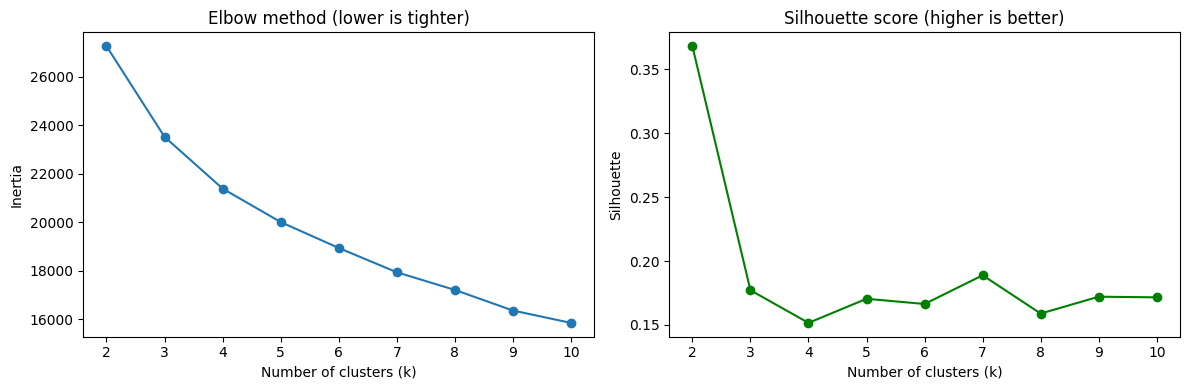

{2: np.float64(0.368), 3: np.float64(0.177), 4: np.float64(0.152), 5: np.float64(0.17), 6: np.float64(0.166), 7: np.float64(0.189), 8: np.float64(0.159), 9: np.float64(0.172), 10: np.float64(0.172)}


In [5]:
k_values = range(2, 11)
inertias, silhouettes = [], []
for k in k_values:
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_, sample_size=3000, random_state=42))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(k_values), inertias, marker="o")
axes[0].set_title("Elbow method (lower is tighter)")
axes[0].set_xlabel("Number of clusters (k)"); axes[0].set_ylabel("Inertia")
axes[1].plot(list(k_values), silhouettes, marker="o", color="green")
axes[1].set_title("Silhouette score (higher is better)")
axes[1].set_xlabel("Number of clusters (k)"); axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()
print(dict(zip(k_values, np.round(silhouettes, 3))))

In [6]:
K = 8
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42).fit(X)
df["cluster"] = kmeans.labels_
print(df["cluster"].value_counts().sort_index())

cluster
0     458
1    1514
2    1136
3    1996
4     204
5     673
6    1218
7    1588
Name: count, dtype: int64


In [7]:
def top_genres(sub, n=3):
    all_genres = pd.Series([g.strip() for s in sub["listed_in"] for g in s.split(",")])
    return ", ".join(all_genres.value_counts().head(n).index)

rows = []
for c in range(K):
    sub = df[df["cluster"] == c]
    rows.append({
        "cluster": c,
        "titles": len(sub),
        "pct_tv_show": round(sub["is_tv_show"].mean() * 100),
        "avg_release_year": round(sub["release_year"].mean()),
        "main_audience": sub["audience"].value_counts().index[0],
        "top_genres": top_genres(sub),
    })
profile = pd.DataFrame(rows)
profile

,cluster,titles,pct_tv_show,avg_release_year,main_audience,top_genres
0,0,458,100,2017,Kids,"Kids' TV, TV Comedies, British TV Shows"
1,1,1514,0,2017,Adult,"International Movies, Comedies, Documentaries"
2,2,1136,0,2016,Adult,"Dramas, International Movies, Independent Movies"
3,3,1996,100,2018,Adult,"International TV Shows, TV Dramas, Crime TV Shows"
4,4,204,5,1973,Teen,"Classic Movies, Dramas, International Movies"
5,5,673,11,1999,Teen,"Comedies, Dramas, International Movies"
6,6,1218,10,2016,Family,"Children & Family Movies, Comedies, Internatio..."
7,7,1588,0,2016,Teen,"International Movies, Dramas, Comedies"


Variance explained: [0.278 0.128] | total: 0.405


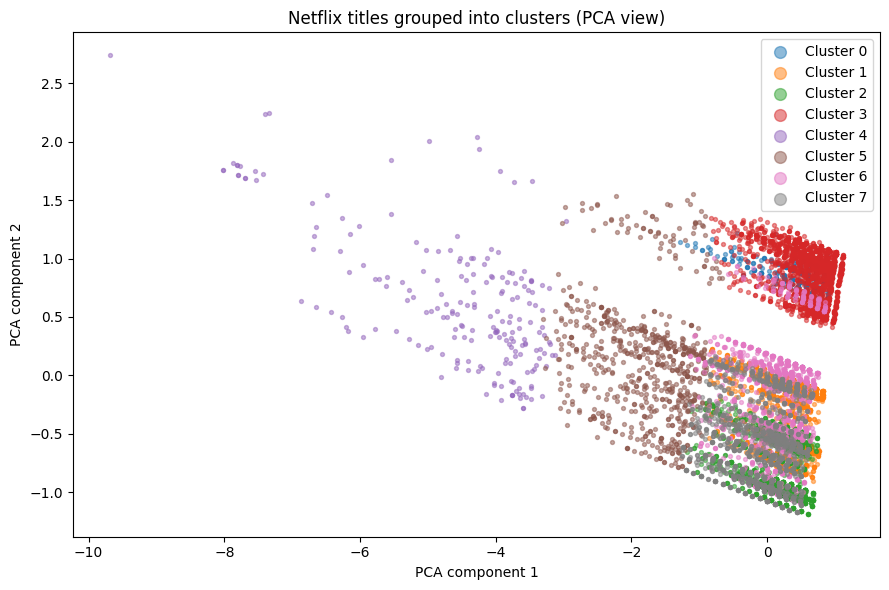

In [8]:
pca = PCA(n_components=2, random_state=42)
points = pca.fit_transform(X)
print("Variance explained:", pca.explained_variance_ratio_.round(3), "| total:", pca.explained_variance_ratio_.sum().round(3))

plt.figure(figsize=(9, 6))
for c in range(K):
    mask = df["cluster"] == c
    plt.scatter(points[mask, 0], points[mask, 1], s=8, alpha=0.5, label=f"Cluster {c}")
plt.legend(markerscale=3)
plt.title("Netflix titles grouped into clusters (PCA view)")
plt.xlabel("PCA component 1"); plt.ylabel("PCA component 2")
plt.tight_layout()
plt.show()

In [9]:
for c in range(K):
    sample = df[df["cluster"] == c]["title"].sample(5, random_state=42).tolist()
    print(f"Cluster {c}:", sample)

Cluster 0: ['Z4', 'Beyblade Burst Turbo', 'The Adventures of Puss in Boots', 'Gigantosaurus', 'City of Ghosts']
Cluster 1: ['The Best of Rafał Rutkowski Olka Szczęśniak', 'Operation Varsity Blues:\xa0The\xa0College\xa0Admissions\xa0Scandal', 'XX', 'Heroes Wanted', 'Alex Fernández: The Best Comedian in the World']
Cluster 2: ['Angry Indian Goddesses', 'Kilo Two Bravo', "I'm No Longer Here", 'Come and Find Me', 'All About Love']
Cluster 3: ['Alone', 'Vampire Knight', 'The Five', 'Monkey Twins', 'The Protector']
Cluster 4: ['The Karate Kid Part II', 'Pioneers: First Women Filmmakers*', 'Little Dragon Maiden', 'Butterfield 8', 'Salaakhen']
Cluster 5: ['Pyaar Ke Side Effects', 'Benji: Off the Leash', 'Bangkok Hell', 'Bad Boys', 'Monty Python: Live at Aspen']
Cluster 6: ['What the Jatt!!', 'Over the Moon', 'The Universe: Ancient Mysteries Solved', 'The Christmas Candle', 'Beat Bugs: All Together Now']
Cluster 7: ['Avengers: Infinity War', 'Madras Café', 'The Sapphires', 'The Yin-Yang Master: